MD# 02 · Leakage audit

**Northvale Credit is a fictional lender; the data is public Lending Club loans.**

Question: which of the 151 raw columns would a lender actually know on the day it decides? A column recorded after issuance (payments, recoveries, a refreshed FICO) makes a model look excellent in testing and useless in production. The rules live in `src/northvale/audit.py`; the full table is `docs/feature_audit.csv`.

In [1]:
import json
import warnings

import pandas as pd
from IPython.display import Image, display

from northvale import config as C

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.max_columns", 20)
m = json.loads(C.METRICS.read_text())


def fig(name, width=900):
    display(Image(filename=str(C.FIGURES / f"{name}.png"), width=width))

In [2]:
audit = pd.read_csv(C.DOCS / "feature_audit.csv")
pd.crosstab(audit["category"], audit["decision"], margins=True)

decision,P&L only,benchmark only,drop,keep,scope filter,split only,target,transformed,All
category,,,,,,,,,
application,0,0,0,58,0,0,0,0,58
application_derived,0,0,0,0,0,0,0,4,4
fairness,0,0,2,0,0,0,0,0,2
free_text,0,0,3,0,0,0,0,0,3
identifier,0,0,3,0,0,0,0,0,3
joint_applicant,0,0,16,0,0,0,0,0,16
late_2015_field,0,0,14,0,0,0,0,0,14
lc_marketplace,1,0,3,0,0,0,0,0,4
lc_pricing,1,2,1,0,0,0,0,0,4


MD## 1. Single-field AUC screen

Each column alone, binned into deciles (plus a missing bin) on the training window; the bin's default rate is the score. An application field above 0.70 on its own would be suspicious: FICO, the strongest real predictor, is about 0.60.

In [3]:
audit.sort_values("single_feature_auc_train", ascending=False, key=lambda s: pd.to_numeric(s, errors="coerce")).head(14)[
    ["column", "category", "decision", "single_feature_auc_train", "screen_flag"]]

,column,category,decision,single_feature_auc_train,screen_flag
52,last_fico_range_low,post_origination,drop,0.8941,suspicious: stronger than any application field
51,last_fico_range_high,post_origination,drop,0.8941,suspicious: stronger than any application field
45,recoveries,post_origination,drop,0.8774,suspicious: stronger than any application field
42,total_rec_prncp,post_origination,drop,0.8138,suspicious: stronger than any application field
48,last_pymnt_amnt,post_origination,drop,0.7885,suspicious: stronger than any application field
41,total_pymnt_inv,post_origination,drop,0.7516,suspicious: stronger than any application field
40,total_pymnt,post_origination,drop,0.7515,suspicious: stronger than any application field
47,last_pymnt_d,post_origination,drop,0.7241,suspicious: stronger than any application field
50,last_credit_pull_d,post_origination,drop,0.7081,suspicious: stronger than any application field
9,sub_grade,lc_pricing,benchmark only,0.6502,NaN


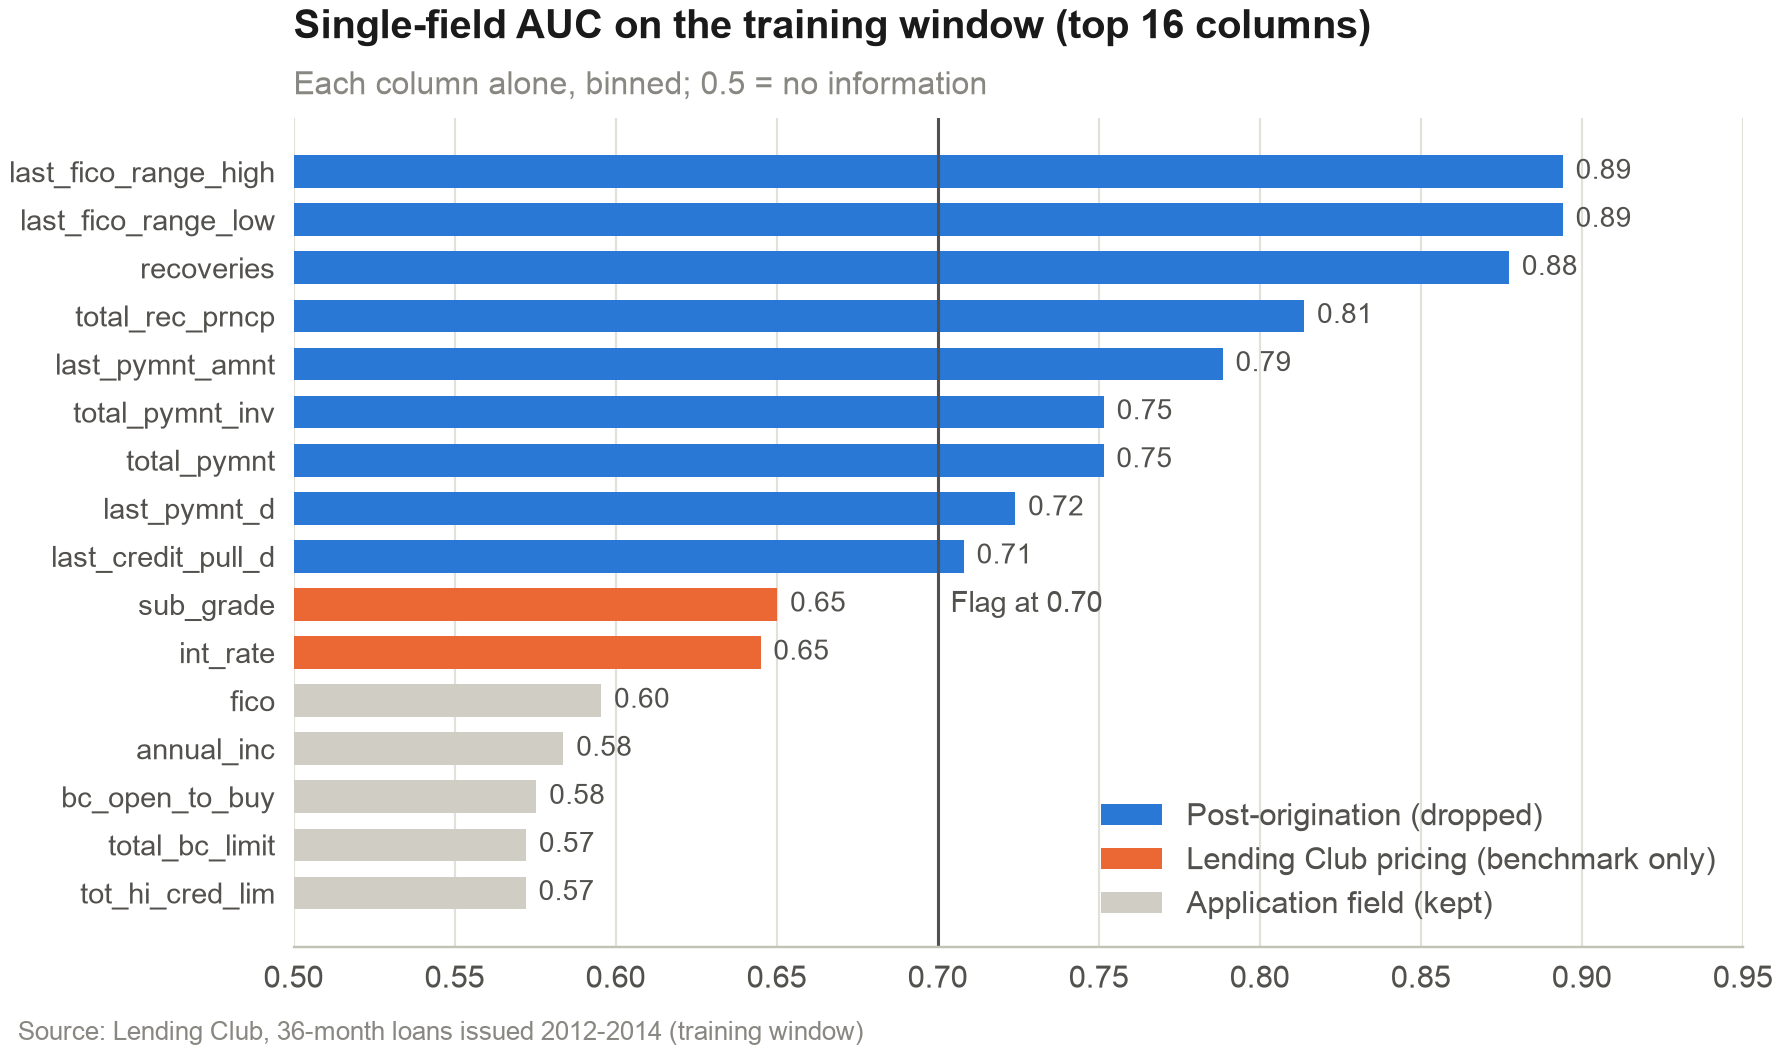

In [4]:
fig("leakage_auc_screen")

MD Every flagged column is post-origination. Lending Club's sub-grade and interest rate come next: they are the incumbent model's output, used as the benchmark and in the P&L, never as features.

## 2. Leakage demonstration

The final LightGBM configuration is retrained with one post-origination field added.

In [5]:
pd.read_csv(C.TABLES / "leakage_demo.csv").assign(label=lambda d: d["label"].str.replace("\n", " "))

,label,field,test_auc
0,Application fields only,NaN,0.7008
1,+ last FICO (refreshed later),last_fico_range_high,0.9476
2,+ principal repaid to date,total_rec_prncp,0.9998


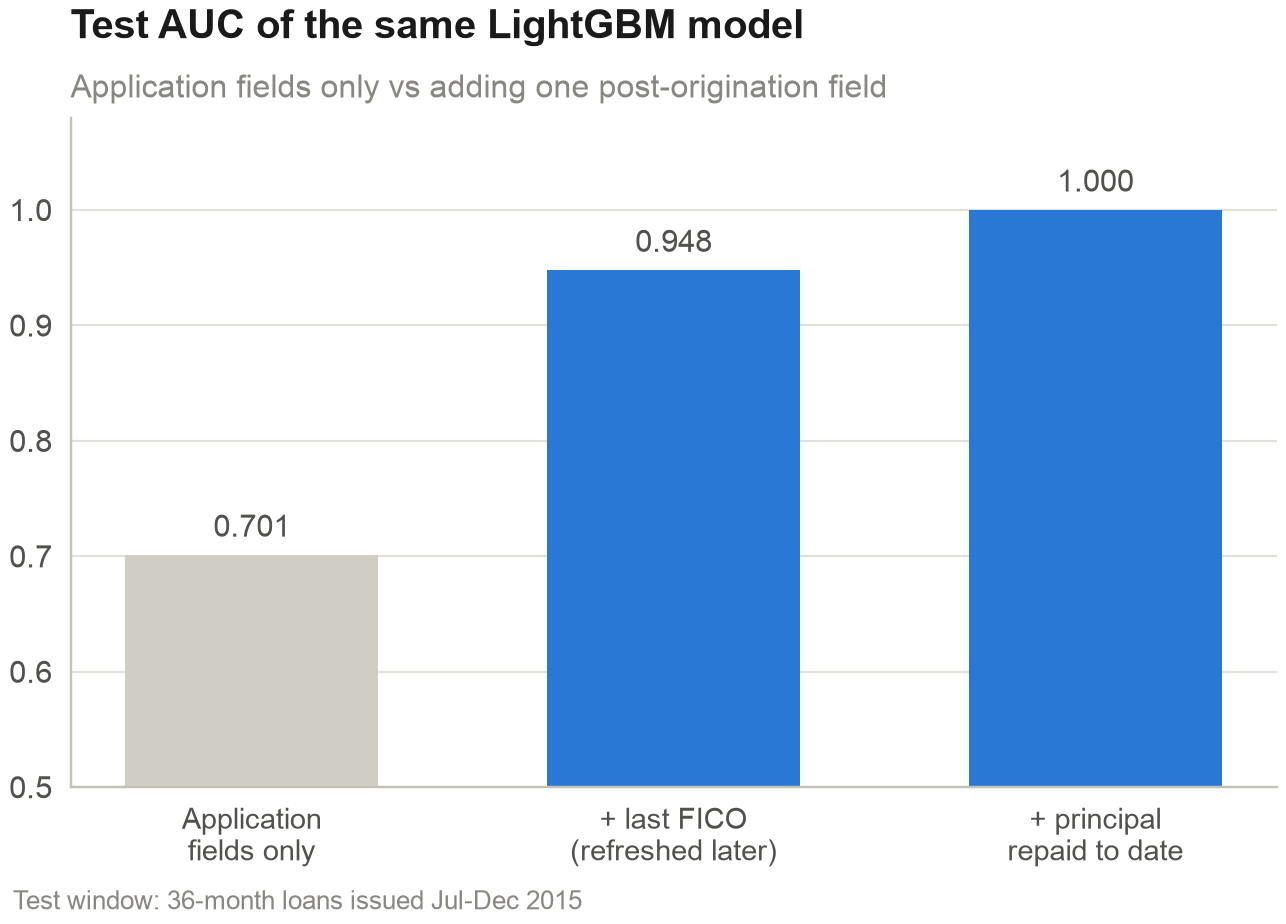

In [6]:
fig("leakage_demo", 600)

MD## 3. Other decisions worth defending

In [7]:
from northvale import audit as A

for col in ["grade", "int_rate", "installment", "zip_code", "addr_state", "emp_title", "open_acc_6m", "funded_amnt_inv", "desc"]:
    cat, avail, decision, reason = A.rule(col)
    print(f"{col:18s} {decision:15s} {reason}")

grade              benchmark only  Lending Club's own risk grade: the incumbent model. Used as the benchmark, not as a feature.
int_rate           P&L only        Price set from the sub-grade; a model using it would copy Lending Club's model. Used in the P&L layer.
installment        drop            Monthly payment = f(amount, int_rate, term), so it encodes the incumbent price.
zip_code           drop            3-digit zip; geography can proxy for race and ethnicity (ECOA / Reg B disparate impact).
addr_state         drop            State of residence; same proxy risk as zip code, and pricing rules differ by state.
emp_title          drop            Free-text job title with very high cardinality and spelling variants; reducing it to groups would take manual coding and can proxy for protected characteristics.
open_acc_6m        drop            Bureau field added in late 2015: empty for every training loan, so the model cannot learn it.
funded_amnt_inv    drop            Amount investor

MD**Answer.** Only fields known at application are kept. Every post-origination, late-2015, joint-applicant, identifier, free-text and geographic-proxy column is dropped with a written reason; the counts are in the table at the top.